# Домашнее задание 9 (16 pts)

Неточный метод Ньютона. На слайдах этой недели — шаг Ньютона, демпфирование, BFGS и L-BFGS. Схема неточного Ньютона перенесена сюда: ниже она записана целиком, на слайдах её нет.

Метод Нестерова с известными $L$ и $\mu$ — слайд недели 8 «Схема, когда известны $L$ и $\mu$». Обратное обновление BFGS и условия Вульфа — слайды этой недели. Здесь повторены только константы, чтобы четыре метода сравнивались в одной постановке.

Во второй задаче гессиан собирают явно и по его структуре выбирают, как решать систему в шаге Ньютона.

Графики и письменный вывод обязательны в каждом пункте. Без комментария баллы за пункт не ставятся.


## Неточный метод Ньютона

### Зачем не решать систему точно

Шаг Ньютона — решение $\mathbf{H}_k\mathbf{d}=-\mathbf{g}_k$, где $\mathbf{g}_k=f'(\mathbf{x}_k)$ и $\mathbf{H}_k=f''(\mathbf{x}_k)$.

- Далеко от минимума квадратичная модель всё равно грубая. Тратить порядка $N^3$ на точное $\mathbf{d}$ нет смысла: снаружи шаг ещё укоротят.
- Близко к минимуму точность решения системы становится важной, но и там часто хватает невязки, сравнимой с $\|\mathbf{g}_k\|$, а не с машинным нулём.
- При большом $N$ гессиан не хранят. Нужна процедура «вектор на вход, $\mathbf{H}\mathbf{v}$ на выход» — та же договорённость, что с матрицей $\mathbf{A}$ у сопряжённых градиентов на неделе 8.

### Допуск на невязку

Направление $\mathbf{d}_k$ считают достаточно точным, если

$$
\|f''(\mathbf{x}_k)\mathbf{d}_k+f'(\mathbf{x}_k)\|
\le
\eta_k\|f'(\mathbf{x}_k)\|,
\qquad
0\le\eta_k<1.
$$

Число $\eta_k$ задаёт, какую долю невязки разрешено оставить. В условиях локальной теоремы Ньютона полный шаг с таким $\mathbf{d}_k$ сходится

- линейно, если $\eta_k\le\bar\eta<1$;
- сверхлинейно, если $\eta_k\to 0$;
- квадратично, если $\eta_k=O(\|f'(\mathbf{x}_k)\|)$.

Это теоремы 2.3 и 3.3 в [R. S. Dembo, S. C. Eisenstat, T. Steihaug, *Inexact Newton Methods*, SIAM J. Numer. Anal. **19** (1982), 400–408](https://doi.org/10.1137/0719025). 
В задании ниже фиксирован один выбор, $\eta_k=\min(0{,}5,\|\mathbf{g}_k\|/\|\mathbf{g}_0\|)$. Он убывает к нулю пропорционально норме градиента, то есть имеет порядок $O(\|\mathbf{g}_k\|)$. Менять его от метода к методу не нужно.

На квадратичной модели невязка внешней итерации умножается на $\eta_k$ точно, потому что шаг берётся вдоль ньютоновского направления.

### Как считать направление

Гессиан не собирают. Систему $\mathbf{H}\mathbf{d}=-\mathbf{g}$ решают сопряжёнными градиентами.

1. Старт внутреннего цикла в базовом варианте — $\mathbf{d}=\mathbf{0}$. Тогда невязка равна $-\mathbf{g}$, и первый шаг идёт вдоль $-\mathbf{g}$. В пункте 3 сравниваются другие стартовые векторы. Для любого ненулевого старта невязку $\mathbf{r}=-(\mathbf{g}+\mathbf{H}\mathbf{d})$ считают заново: подставлять прошлый вектор невязки нельзя, правая часть уже другая.
2. Остановка: $\|\mathbf{H}\mathbf{d}+\mathbf{g}\|\le\eta\|\mathbf{g}\|$, либо исчерпан предел итераций $N$.
3. Если для пробного направления $\mathbf{p}$ оказалось $\mathbf{p}^\top\mathbf{H}\mathbf{p}\le 0$, цикл прерывают. Гессиан вдоль $\mathbf{p}$ не положительно определён, и шаг СГ по этой формуле не определён. Если ни одного успешного шага ещё не было, возвращают $-\mathbf{g}$ при нулевом старте и сам стартовый вектор, когда $\langle\mathbf{g},\mathbf{d}\rangle<0$. Иначе возвращают уже построенное $\mathbf{d}$.
4. После выхода проверяют спуск: если $\langle\mathbf{g},\mathbf{d}\rangle\ge 0$, направление заменяют на $-\mathbf{g}$. Нулевой старт при $\mathbf{H}\succ 0$ эту проверку проходит сам. Ненулевой старт — не всегда.
5. Снаружи — поиск Армихо с пробой $\alpha=1$, $c_1=10^{-4}$, укорочение $\rho=1/2$. Неточный шаг тоже может быть слишком длинным.

Один внутренний шаг стоит одного умножения на гессиан, который явно не собирается.


## Задача 1 (10 pts). Смазанный снимок с битыми пикселями

На неделе 8 тот же кадр восстанавливался квадратичной невязкой $\tfrac12\|\mathbf{K}\mathbf{u}-\mathbf{b}\|^2$. Квадрат считает битый пиксель обычным измерением: один выброс тянет за собой целое пятно. Здесь невязка растёт на больших остатках линейно, а не квадратично,

$$
f(\mathbf{u})
=
\sum_{i=1}^{N}\log\cosh\bigl((\mathbf{K}\mathbf{u}-\mathbf{b})_i\bigr)
+
\frac{\mu}{2}\|\mathbf{u}\|^2,
\qquad
N=n^2.
$$

Смазывание имитируется той же периодической гауссовой свёрткой, что в задании 8. 
Ядро чётное, поэтому $\mathbf{K}=\mathbf{K}^\top$, а `blur_eigs` возвращает вещественные собственные значения. Резкий кадр — центральный квадрат `campus.jpg`, прореженный до $n\times n$: из каждого блока берётся один пиксель, без усреднения. В $f$ он не входит.

Градиент, $r=\mathbf{K}\mathbf{u}-\mathbf{b}$, уже есть в `gradient`:

$$
f'(\mathbf{u})
=
\mathbf{K}\tanh(r)+\mu\mathbf{u}.
$$

Умножения на гессиан в коде нет. Его выводят и программируют в пункте 1.

Вторая производная $\log\cosh$ равна $\mathrm{sech}^2$ и лежит в $(0,1]$. Ядро нормировано на единицу, поэтому $\|\mathbf{K}\|_2=\max_i|\lambda_i(\mathbf{K})|$. Код печатает это число: оно равно 1 с точностью до округления Фурье. Отсюда $L$-гладкость и сильная выпуклость со штрафом $\mu$,

$$
L=\|\mathbf{K}\|_2^2+\mu,
\qquad
\kappa=\frac{L}{\mu}.
$$

Константа сильной выпуклости — именно штраф $\mu$. Слагаемое со свёрткой положительно полуопределено и нижнюю оценку не улучшает.

Точный Ньютон в этом задании собирает гессиан столбцами: $i$-й столбец равен `hessian_vec` на $i$-м орте. Затем матрицу симметризуют, $(\mathbf{H}+\mathbf{H}^\top)/2$, и решают систему. Ускорять сборку диагонализацией свёртки не нужно. Сравнивается цена плотной матрицы с ценой нескольких умножений.

Старт всех методов — нулевой вектор. Допуск один: $\|\mathbf{g}_k\|/\|\mathbf{g}_0\|\le 10^{-6}$. Время — `time.perf_counter` вокруг цикла метода, вместе с поиском шага и внутренними сопряжёнными градиентами, без построения графиков.


1. **(2 pts)** Реализуйте `hessian_vec(u, v, eigvals, b, mu)`: по вектору `v` она возвращает $f''(\mathbf{u})\mathbf{v}$ и не собирает матрицу $N\times N$.

   Проверка — случайные $\mathbf{u}$ и $\mathbf{v}$ той же длины и шаг $\varepsilon=10^{-6}$. Сравните свой результат с центральной разностью

$$
\frac{f'(\mathbf{u}+\varepsilon\mathbf{v})-f'(\mathbf{u}-\varepsilon\mathbf{v})}{2\varepsilon}.
$$

   В комментарии запишите формулу произведения, относительную ошибку проверки и сколько вызовов `apply_K` стоит одно умножение. В методах ниже используйте `hessian_vec`, а не конечную разность.

2. **(3 pts)** Возьмите $n=128$, `sigma_blur = 2.0`, $\mu=10^{-3}$, `seed = 0`. Посчитайте $\kappa$.

   Запустите четыре метода.

   - Демпфированный Ньютон. Сборка плотного гессиана $\mathbf{H}$. Поиск Армихо: проба $\alpha=1$, $c_1=10^{-4}$, $\rho=1/2$. Бюджет — 20 внешних шагов.
   - Неточный Ньютон с нулевым стартом СГ и $\eta_k=\min(0{,}5,\|\mathbf{g}_k\|/\|\mathbf{g}_0\|)$. Тот же Армихо. Внутренний бюджет — $N$ умножений на гессиан на один внешний шаг. Внешний бюджет — 20 шагов.
   - Нестеров с известными $L$ и $\mu$: упреждение $\mathbf{y}_k=\mathbf{x}_k+\beta(\mathbf{x}_k-\mathbf{x}_{k-1})$, затем шаг $1/L$ из $\mathbf{y}_k$, $\beta=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$, $\mathbf{x}_{-1}=\mathbf{x}_0$. Бюджет — 2000 итераций.
   - BFGS. Обратное обновление со слайда, условия Вульфа с $c_1=10^{-4}$, $c_2=0{,}9$, проба $\alpha=1$. После первого принятого шага с $\mathbf{y}^\top\mathbf{s}>0$ положите $\mathbf{H}\leftarrow\gamma\mathbf{I}$, $\gamma=(\mathbf{s}^\top\mathbf{y})/(\mathbf{y}^\top\mathbf{y})$, и уже к этой матрице примените обновление. При $\mathbf{y}^\top\mathbf{s}\le 0$ обновление пропускайте. Если $\langle\mathbf{g},\mathbf{d}\rangle\ge 0$, берите $\mathbf{d}=-\mathbf{g}$. Бюджет — 250 итераций.

   Если бюджет кончился раньше допуска, так и запишите.

   На одном графике с логарифмической осью $y$ — относительная норма градиента против номера итерации. Для обоих Ньютонов номер — внешний шаг, для Нестерова и BFGS — шаг метода, без укорочений поиска. На втором таком же графике по горизонтали — секунды от старта метода.

   В таблице: итерации до допуска, секунды, финальная относительная норма. Для неточного Ньютона добавьте суммарное число вызовов `hessian_vec`.

   Рядом с наблюдением $\mathbf{b}$ покажите резкий кадр и восстановление точного Ньютона.

   В комментарии: кто впереди по итерациям и кто по времени; почему метод с меньшим числом итераций может быть медленнее; как число шагов Нестерова соотносится с $\sqrt{\kappa}$, а хвост Ньютона — с локальной квадратичной фазой. По кадру: остались ли битые пиксели яркими пятнами.

3. **(3 pts)** Та же задача, $n=128$, тот же $\eta_k$, тот же допуск и те же бюджеты. Меняется только стартовый вектор СГ внутри неточного Ньютона. Принятый шаг $\mathbf{s}_{k-1}=\mathbf{x}_k-\mathbf{x}_{k-1}$ уже включает множитель Армихо. На первом внешнем шаге все четыре схемы стартуют с нуля.

   - Нулевой старт, $\mathbf{d}_0=\mathbf{0}$.
   - Прошлый шаг, $\mathbf{d}_0=\mathbf{s}_{k-1}$.
   - Масштабированный прошлый шаг, $\mathbf{d}_0=\mathbf{s}_{k-1}\,\|\mathbf{g}_k\|/\|\mathbf{g}_{k-1}\|$.
   - Масштабированный шаг с отказом. Пробный вектор — тот же, что в предыдущей схеме. Если $\|\mathbf{H}\mathbf{d}_0+\mathbf{g}_k\|<\|\mathbf{g}_k\|$, стартуйте с него, иначе с нуля. Проверочное умножение входит в счётчик. Невязка нулевого вектора равна $\|\mathbf{g}_k\|$, поэтому порог сравнивает пробный старт с нулевым.

   Для ненулевого $\mathbf{d}_0$ невязка пересчитывается, и это умножение тоже считается. Правило отрицательной кривизны и замена направления на $-\mathbf{g}$ при $\langle\mathbf{g},\mathbf{d}\rangle\ge 0$ — из раздела выше.

   На одном графике — число вызовов `hessian_vec` на внешнем шаге, четыре линии. В таблице: внешние итерации, суммарные умножения, секунды и сколько раз проверка спуска заменила направление на $-\mathbf{g}$.

   В комментарии: на каких внешних шагах схемы расходятся и почему прошлый шаг Ньютона может быть для СГ хуже нуля. Опирайтесь на невязку нулевого старта.

4. **(2 pts)** Повторите пункт 2 при $n=256$. Те же $\sigma$, $\mu$, `seed`, допуск. Неточный Ньютон — только с нулевым стартом. Точный Ньютон запускайте один раз. Если он не уложился в 3 минуты, остановите и запишите время и достигнутую норму градиента.

   Таблица — итерации и секунды. В комментарии: сохранился ли порядок методов по итерациям и как время точного Ньютона выросло с $N=n^2$. Одно умножение на гессиан — две свёртки, сборка матрицы — $N$ таких умножений.


N = 65536,  ||K|| = 1.000000,  L = 1.001000,  kappa = 1001.0


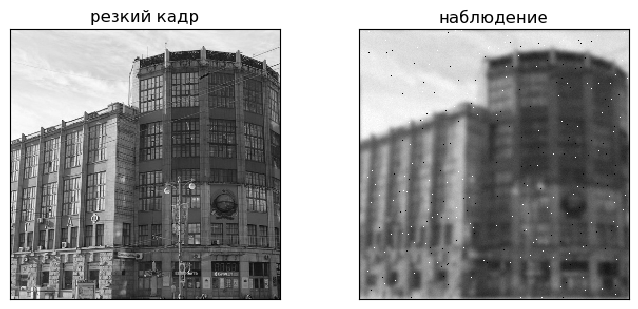

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt


def blur_eigs(n, sigma):
    """Собственные значения гауссовой свёртки с периодической границей."""
    ax = np.arange(n)
    dist = np.minimum(ax, n - ax).astype(float)
    xx, yy = np.meshgrid(dist, dist, indexing="ij")
    ker = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    ker /= ker.sum()
    return np.fft.fft2(ker).real


def apply_K(u, eigvals):
    """Одна свёртка. eigvals — то, что вернул blur_eigs."""
    U = np.asarray(u, dtype=float).reshape(eigvals.shape)
    return np.fft.ifft2(eigvals * np.fft.fft2(U)).real.ravel()


def load_sharp(path, n):
    """Яркость campus.jpg: центральный квадрат, один пиксель из блока.
    Усреднения нет, иначе резкий кадр уже смазан. В f не входит.
    """
    rgb = np.asarray(plt.imread(path), dtype=float)
    if rgb.max() > 1.5:
        rgb = rgb / 255.0
    gray = rgb[..., :3] @ np.array([0.2989, 0.5870, 0.1140])
    height, width = gray.shape
    side = min(height, width)
    top = (height - side) // 2
    left = (width - side) // 2
    gray = gray[top:top + side, left:left + side]
    block = side // n
    gray = gray[: block * n, : block * n]
    return gray[block // 2::block, block // 2::block][:n, :n]


def logcosh(r):
    """Устойчивый log(cosh r): при большом |r| это |r| - log 2."""
    a = np.abs(r)
    return a + np.log1p(np.exp(-2.0 * a)) - np.log(2.0)


def value(u, eigvals, b, mu):
    r = apply_K(u, eigvals) - b
    return float(np.sum(logcosh(r)) + 0.5 * mu * np.dot(u, u))


def gradient(u, eigvals, b, mu):
    r = apply_K(u, eigvals) - b
    return apply_K(np.tanh(r), eigvals) + mu * u


# Пункт 1: def hessian_vec(u, v, eigvals, b, mu) возвращает f''(u) v.


def make_observation(n, sigma, mu, seed=0, path="campus.jpg"):
    """Наблюдение b: смазывание слабый гауссов шум и n битых пикселей."""
    eigvals = blur_eigs(n, sigma)
    sharp = load_sharp(path, n).ravel()
    rng = np.random.default_rng(seed)
    blurred = apply_K(sharp, eigvals)
    b = blurred + 0.01 * rng.normal(size=blurred.shape)
    broken = rng.choice(n * n, size=n, replace=False)
    b[broken] += rng.choice([-1.0, 1.0], size=n) * rng.uniform(0.8, 1.5, size=n)
    spec = float(np.max(np.abs(eigvals)))
    L = spec ** 2 + mu
    return {
        "eigvals": eigvals,
        "b": b,
        "sharp": sharp,
        "mu": mu,
        "L": L,
        "kappa": L / mu,
        "spec": spec,
    }


n = 256
sigma_blur = 2.0
mu_penalty = 1e-3
problem = make_observation(n, sigma_blur, mu_penalty, seed=0)
print(
    f"N = {n * n},  ||K|| = {problem['spec']:.6f},  "
    f"L = {problem['L']:.6f},  kappa = {problem['kappa']:.1f}"
)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2))
axes[0].imshow(
    problem["sharp"].reshape(n, n), cmap="gray", vmin=0, vmax=1, interpolation="nearest"
)
axes[0].set_title("резкий кадр")
axes[1].imshow(
    problem["b"].reshape(n, n), cmap="gray", vmin=0, vmax=1, interpolation="nearest"
)
axes[1].set_title("наблюдение")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

# Место для вашего решения


## Задача 2 (6 pts). Число страховых случаев

У страховой $m$ клиентов. У клиента $i$ вектор признаков $\mathbf{x}_i$ длины $n$ и число обращений $y_i$ за год. Обращения моделируют пуассоновской случайной величиной со средним $\exp(\mathbf{x}_i^\top\boldsymbol{\beta})$. Штраф $\mu$ не даёт коэффициентам разъехаться, когда признаков больше, чем клиентов. Минимизируется

$$
f(\boldsymbol{\beta})
=
\sum_{i=1}^{m}
\bigl(\exp(\mathbf{x}_i^\top\boldsymbol{\beta})-y_i\mathbf{x}_i^\top\boldsymbol{\beta}\bigr)
+
\frac{\mu}{2}\|\boldsymbol{\beta}\|^2.
$$

Так оценивают число страховых случаев, обращений в поддержку, поездок. Градиент считает `gradient_poisson`. Гессиан в коде не задан.

1. **(2 pts)** Выведите $f''(\boldsymbol{\beta})$ и реализуйте `hessian_poisson(beta, X, y, mu)`. Функция возвращает плотную матрицу $n\times n$.

   На `make_poisson(m=40, n=80, mu=1, seed=1)` в нуле возьмите случайный вектор $\mathbf{v}$ и сравните $\mathbf{H}\mathbf{v}$ с центральной разностью градиента при $\varepsilon=10^{-6}$. Относительная ошибка должна быть мала.

   По собранной матрице ответьте: из каких слагаемых она состоит; какое слагаемое обращается сразу; какой размер у второго слагаемого; как соотносятся $m$ и $n$. Предложите, как решать $f''(\boldsymbol{\beta})\mathbf{d}=-\mathbf{g}$ в шаге Ньютона, не храня матрицу $n\times n$.

   Подсказка: для обратимых $\mathbf{A}$ и $\mathbf{C}$ справедлива формула Шермана–Моррисона–Вудбери

$$
(\mathbf{A}+\mathbf{U}\mathbf{C}\mathbf{V})^{-1}
=
\mathbf{A}^{-1}
-
\mathbf{A}^{-1}\mathbf{U}
(\mathbf{C}^{-1}+\mathbf{V}\mathbf{A}^{-1}\mathbf{U})^{-1}
\mathbf{V}\mathbf{A}^{-1}.
$$

   В комментарии запишите формулу гессиана, выбранные $\mathbf{A}$, $\mathbf{U}$, $\mathbf{C}$, $\mathbf{V}$ и размер системы, которую предлагаете факторизовать.

2. **(2 pts)** Реализуйте `newton_direction(beta, X, y, mu)` способом из пункта 1. Она возвращает $-\,f''(\boldsymbol{\beta})^{-1}\mathbf{g}$.

   На тех же данных и в том же нуле сравните направление с `numpy.linalg.solve` по матрице из пункта 1. Относительная ошибка должна быть меньше $10^{-8}$.

3. **(2 pts)** Демпфированный Ньютон из нуля. Проба $\alpha=1$, $c_1=10^{-4}$, укорочение вдвое, допуск $\|\mathbf{g}\|/\|\mathbf{g}_0\|\le 10^{-6}$, бюджет --- 15 шагов. Два варианта одного и того же направления: способ из пункта 1 и плотная факторизация гессиана. Данные `make_poisson(m=200, n=2000, mu=1, seed=0)`.

   На одном графике с логарифмической осью $y$ --- относительная норма градиента против номера шага, обе кривые. В таблице --- число шагов и секунды.

   В комментарии: совпали ли траектории и почему; какая схема быстрее; как её цена относится к $m^3$, к $m^2 n$ и к $n^3$.


In [ ]:
import numpy as np


def make_poisson(m, n, mu, seed=0):
    """Признаки клиентов, числа обращений и штраф. 
    Истинный beta в f не входит."""
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(m, n)) / np.sqrt(n)
    beta_true = np.zeros(n)
    beta_true[:6] = np.array([0.6, -0.4, 0.3, 0.5, -0.2, 0.25])
    y = rng.poisson(np.exp(X @ beta_true)).astype(float)
    return X, y, mu


def value_poisson(beta, X, y, mu):
    z = X @ beta
    return float(np.sum(np.exp(z) - y * z) + 0.5 * mu * np.dot(beta, beta))


def gradient_poisson(beta, X, y, mu):
    w = np.exp(X @ beta)
    return X.T @ (w - y) + mu * beta

# Место для вашего решения
